# Why this model works

**The input file is a POLAR collaboration product not distributed with the package.** This notebook reads `data/polarization_plus_data_170114A.root`, the GEANT4 response of GRB 170114A produced by the POLAR collaboration (Produit et al. 2018; Li et al. 2018; Kole et al. 2020), from the untracked folder `examples/data/`; place your own copy there to run it. The notebook ships with its stored outputs, so it can be read without the file.

This notebook tells the story of the MENHAG response model in one worked example, step by step. The object we work with throughout is the ASAD, the azimuthal scattering angle distribution: a histogram of the azimuthal direction eta into which photons Compton scatter inside the detector. A polarized beam modulates this histogram; an unpolarized beam does not.

The worked example follows the single-ASAD comparison figure of the accompanying paper: GRB 170114A seen by POLAR at 150 keV, from 27.25 degrees off the detector axis (azimuth 6.07 degrees, the incidence geometry taken from the instrument attitude recorded with the data products), with the erf(25, 75) threshold gate. One convention holds for every figure: each curve is scaled to the same total counts as the measured unpolarized ASAD, so all panels are directly comparable by eye. The colours, linestyles and markers are the roles of the paper's figures (`menhag.palette`): blue circles for a simulation or the data, vermillion dashes and squares for the analytic construction of this work, orange dots for a second curve drawn for comparison, grey for a per-bin quantity, and a thin black dotted line for an exact reference.

The plan, cell by cell:

1. what the ideal polarized and unpolarized ASADs look like with no instrument at all, straight from the scattering physics;
2. what the detection threshold alone does to those shapes, before any detector geometry enters;
3. what the real instrument's unpolarized ASAD looks like instead;
4. the instrumental imprint on its own, peeled off by comparing the two;
5. how the polarized signal is put back on top with the kernel, and how the prediction compares against the GEANT4-simulated polarized ASAD;
6. the same comparison repeated across several polarization angles.

**References for the instrument and the data used here:** the POLAR detector is described in Produit et al. 2018 (Nucl. Instrum. Meth. A 877, 259); its in-orbit performance and calibration, including the detection thresholds we use for the gate, in Li et al. 2018 (Nucl. Instrum. Meth. A 900, 8); and the GRB observations and polarization catalog in Kole et al. 2020 (Astron. Astrophys. 644, A124). The response model demonstrated here is derived and validated in the accompanying paper (Zaid et al.), which also defines every symbol used below.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from menhag import build_ideal, build_single, calculate_reduced_chi_squared, palette
from menhag.adapters import PolarRootAdapter
from menhag.gates import load_gate_json

palette.apply(plt)   # the rc block and roles of the paper's figures

# The worked example of the paper's single-ASAD comparison figure:
DELTA = 27.25   # zenith angle from the detector normal, degrees
LAMBDA = 6.07   # azimuth around the detector normal, degrees
ENERGY = 150.0  # photon energy, keV

# The POLAR threshold gate of the paper, loaded from its description file.
GATE, GATE_INFO = load_gate_json("polar_gate.json")
print("gate:", GATE)

# The POLAR file (see the note at the top) and the count normalization of
# its histograms: stored contents are raw counts divided by f = 1591, which
# enters only the statistical error bars, sigma = sqrt(n f) / f.
POLAR_FILE = os.path.join("data", "polarization_plus_data_170114A.root")
NORM_FACTOR = 1591.0
polar = PolarRootAdapter(POLAR_FILE, norm_factor=NORM_FACTOR)

# The measured unpolarized ASAD sets the common count scale used by
# every figure in this notebook.
unp = polar.load_unpolarized(ENERGY)
edges = unp.bin_edges
eta = unp.bin_centers
m_unp = unp.counts
m_unp_err = unp.errors
TOTAL = m_unp.sum()
print(f"common count scale: {TOTAL:.1f} total counts "
      f"(the measured unpolarized ASAD at {ENERGY:.0f} keV)")

def scaled(curve):
    """Scale any curve to the common total counts of this notebook."""
    curve = np.asarray(curve, dtype=float)
    return curve * TOTAL / curve.sum()


gate: ErfGate(mu=25.0, sigma=75.0)


common count scale: 71.3 total counts (the measured unpolarized ASAD at 150 keV)


## 1. The ideal curves: no instrument at all

First, the pure physics. For a 150 keV photon coming from our source direction, the Klein-Nishina cross-section already fixes the shape of the ASAD before any instrument is involved. `build_ideal` computes both curves: the ASAD of a fully polarized beam and the ASAD of an unpolarized beam. Because the source is 27 degrees off axis, even the unpolarized curve is not flat: the geometry alone imprints a once-per-turn (360 degree) wave. The polarized curve carries, on top of that, the twice-per-turn (180 degree) modulation that polarimetry measures.

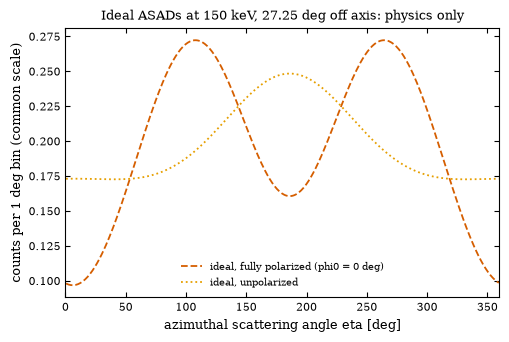

In [ ]:
ideal = build_ideal(ENERGY, DELTA, LAMBDA, phi0=0.0, threshold=None, n_bins=360)

fig, ax = plt.subplots(figsize=(5.6, 3.5))
ax.plot(ideal["eta_deg"], scaled(ideal["phi_pol"]), color=palette.c("mode1"),
        ls=palette.ls("mode1"), label="ideal, fully polarized (phi0 = 0 deg)")
ax.plot(ideal["eta_deg"], scaled(ideal["phi_unp"]), color=palette.c("comparison"),
        ls=palette.ls("comparison"), label="ideal, unpolarized")
ax.set_xlim(0, 360)
ax.set_xlabel("azimuthal scattering angle eta [deg]")
ax.set_ylabel("counts per 1 deg bin (common scale)")
ax.set_title("Ideal ASADs at 150 keV, 27.25 deg off axis: physics only")
ax.legend(frameon=False)
plt.show()
# Caption: the unpolarized curve shows the geometric 360 degree wave of
# off-axis incidence; the polarized curve adds the 180 degree
# polarization modulation on top of it. Both are scaled to the common
# total counts stated in the introduction.


## 2. What the threshold alone does

The first instrument property we add is the detection threshold: a Compton event only counts if both of its energy deposits are detectable, and near the threshold that acceptance turns on gradually rather than as a step. The erf(25, 75) gate describes exactly that turn-on. The figure below shows the ideal curves before and after the gate, with no detector geometry involved yet, one panel per beam: the threshold alone reshapes the ASAD, because it removes preferentially the scattering angles whose smaller deposit is hardest to detect.

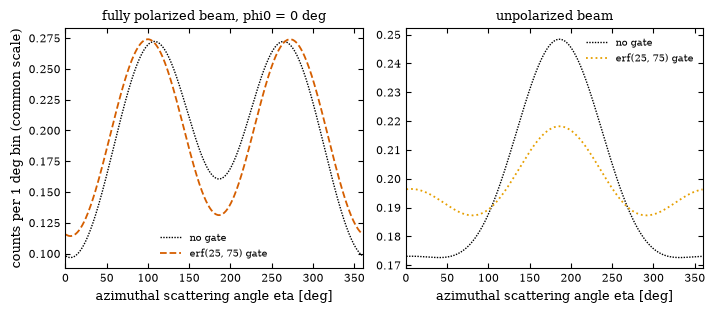

In [ ]:
gated = build_ideal(ENERGY, DELTA, LAMBDA, phi0=0.0, threshold=GATE, n_bins=360)

fig, (ax_pol, ax_unp) = plt.subplots(1, 2, figsize=(7.2, 3.2), sharex=True)
ax_pol.plot(ideal["eta_deg"], scaled(ideal["phi_pol"]), color=palette.c("truth"),
            ls=palette.ls("truth"), lw=1.0, label="no gate")
ax_pol.plot(gated["eta_deg"], scaled(gated["phi_pol"]), color=palette.c("mode1"),
            ls=palette.ls("mode1"), label="erf(25, 75) gate")
ax_pol.set_title("fully polarized beam, phi0 = 0 deg")
ax_unp.plot(ideal["eta_deg"], scaled(ideal["phi_unp"]), color=palette.c("truth"),
            ls=palette.ls("truth"), lw=1.0, label="no gate")
ax_unp.plot(gated["eta_deg"], scaled(gated["phi_unp"]), color=palette.c("comparison"),
            ls=palette.ls("comparison"), label="erf(25, 75) gate")
ax_unp.set_title("unpolarized beam")
for ax in (ax_pol, ax_unp):
    ax.set_xlim(0, 360)
    ax.set_xlabel("azimuthal scattering angle eta [deg]")
    ax.legend(frameon=False)
ax_pol.set_ylabel("counts per 1 deg bin (common scale)")
fig.tight_layout()
plt.show()
# Caption: the thin dotted curves are the ungated ideal shapes, the
# coloured curves the same shapes with the erf(25, 75) threshold gate
# applied. This is what the threshold by itself does to the ASAD, before
# any detector geometry enters the picture.


## 3. What the real instrument measures for an unpolarized beam

Now the real detector. The POLAR file holds the unpolarized ASAD of the full POLAR GEANT4 mass model at the same energy and source direction: the photons scatter in a segmented plastic array, deposits fall below thresholds, events are selected, and the recorded azimuth is binned into 360 one-degree bins. The gated ideal curve from the previous section is what the physics plus the threshold predict; everything the measured curve does beyond that is the detector itself.

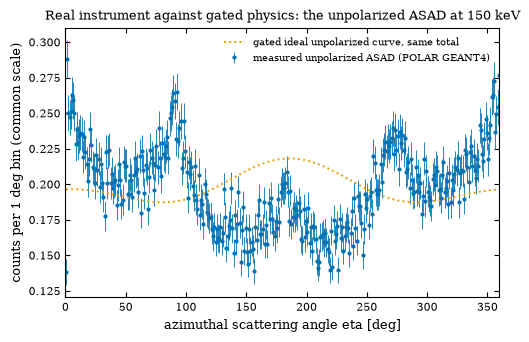

In [ ]:
ideal_unp_scaled = scaled(gated["phi_unp"])

fig, ax = plt.subplots(figsize=(5.6, 3.5))
ax.errorbar(eta, m_unp, yerr=m_unp_err, fmt=palette.mk("reference"), ms=2, lw=0.6,
            color=palette.c("reference"), label="measured unpolarized ASAD (POLAR GEANT4)")
ax.plot(gated["eta_deg"], ideal_unp_scaled, color=palette.c("comparison"),
        ls=palette.ls("comparison"), lw=1.4, label="gated ideal unpolarized curve, same total")
ax.set_xlim(0, 360)
ax.set_xlabel("azimuthal scattering angle eta [deg]")
ax.set_ylabel("counts per 1 deg bin (common scale)")
ax.set_title("Real instrument against gated physics: the unpolarized ASAD at 150 keV")
ax.legend(frameon=False)
plt.show()
# Caption: the measured curve follows the gated physics shape but carries
# extra structure on top: that extra structure is the instrument.


## 4. The instrumental imprint on its own

Dividing the measured unpolarized curve by the gated ideal one isolates the instrumental imprint I(eta). Because the threshold is already divided out (both curves carry the same gate), what remains is detector geometry and efficiency only: the segmented bar array, the light collection, the readout, the event selection. This is the piece no analytic formula tries to reproduce; it is measured, and it will be carried along unchanged into every polarized prediction. That is the key idea of the method: the instrument does not care about polarization, so its imprint on a polarized beam is the same one we just measured with an unpolarized beam.

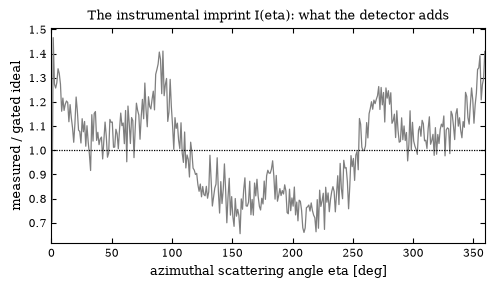

In [ ]:
imprint = m_unp / ideal_unp_scaled

fig, ax = plt.subplots(figsize=(5.6, 2.8))
ax.plot(eta, imprint, lw=0.9, color=palette.c("auxiliary"), ls="-")
ax.axhline(1.0, color=palette.c("truth"), ls=palette.ls("truth"), lw=0.9)
ax.set_xlim(0, 360)
ax.set_xlabel("azimuthal scattering angle eta [deg]")
ax.set_ylabel("measured / gated ideal")
ax.set_title("The instrumental imprint I(eta): what the detector adds")
plt.show()
# Caption: the ratio of the measured unpolarized ASAD to the gated ideal
# curve, with the dotted line at one. The threshold is already divided
# out, so this imprint isolates detector geometry and efficiency only; the
# fourfold pattern reflects the square geometry of the bar array.


## 5. Putting the polarized signal back, and testing it

To predict what a fully polarized beam would look like, the kernel multiplies the measured unpolarized curve, bin by bin, by the ratio of the gated polarized to the gated unpolarized physics curves, and then restores the total counts. In one line: keep the measured instrument, swap the physics. `build_single` does exactly this.

The test is immediate: the POLAR file also holds the fully polarized ASAD of the same GEANT4 mass model at polarization angle 0, simulated independently. It never entered our prediction; it is the ground truth. The figure below is the same comparison as the single-ASAD comparison figure of the accompanying paper: the ASAD overlay on top, the per-bin chi-squared underneath, and the reduced chi-squared quoted. Values near one mean agreement within the combined statistical uncertainties.

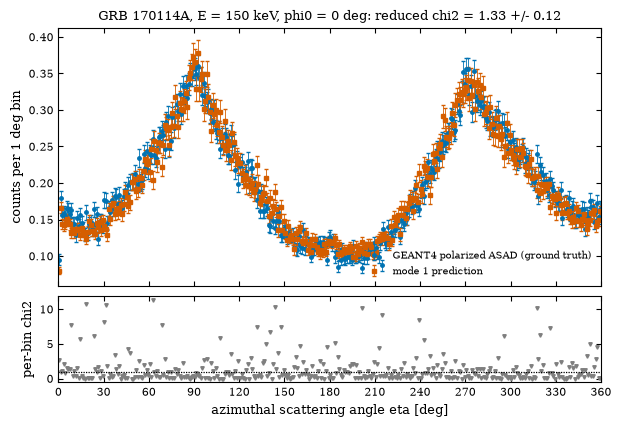

In [ ]:
PHI0 = 0.0
pred, pred_err = build_single(
    m_unp, edges, energy=ENERGY, delta=DELTA, lambda_=LAMBDA,
    phi0=PHI0, threshold=GATE, errors=m_unp_err,
)

g4_asad = polar.load_polarized(ENERGY, PHI0)
g4, g4_err = g4_asad.counts, g4_asad.errors

chi2, chi2_err, nbins = calculate_reduced_chi_squared(g4, g4_err, pred, pred_err, norm=NORM_FACTOR)
var = pred / NORM_FACTOR + pred_err ** 2
per_bin = np.where(var > 0, (g4 - pred) ** 2 / var, 0.0)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(7.0, 4.6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06})
ax_top.errorbar(eta, g4, yerr=g4_err, fmt=palette.mk("reference"), ms=2.5,
                color=palette.c("reference"), elinewidth=0.6, capsize=1.2,
                label="GEANT4 polarized ASAD (ground truth)")
ax_top.errorbar(eta, pred, yerr=pred_err, fmt=palette.mk("mode1"), ms=2.5,
                color=palette.c("mode1"), elinewidth=0.6, capsize=1.2,
                label="mode 1 prediction")
ax_top.set_ylabel("counts per 1 deg bin")
ax_top.set_title(f"GRB 170114A, E = {ENERGY:.0f} keV, phi0 = {PHI0:.0f} deg: "
                 f"reduced chi2 = {chi2:.2f} +/- {chi2_err:.2f}")
ax_top.legend(loc="lower right", frameon=False)
ax_bot.plot(eta, per_bin, ls="none", marker=palette.mk("auxiliary"), ms=2.5,
            color=palette.c("auxiliary"))
ax_bot.axhline(1.0, color=palette.c("truth"), ls=palette.ls("truth"), lw=0.9)
ax_bot.set_xlim(0, 360)
ax_bot.xaxis.set_major_locator(plt.MultipleLocator(30))
ax_bot.set_xlabel("azimuthal scattering angle eta [deg]")
ax_bot.set_ylabel("per-bin chi2")
plt.show()
# Caption: this comparison matches the single-ASAD comparison figure of
# the paper: the same GRB, energy, source direction, gate and
# polarization angle, with the same two-panel layout. The per-bin
# chi-squared uses the paper's convention, the Poisson variance of the
# simulation at the model expectation plus the propagated variance of
# the prediction.


## 6. Any polarization angle from the same single input

Nothing in the recipe was special to angle zero. The same measured unpolarized curve predicts the polarized ASAD at any angle; below we repeat the comparison for six angles, all at the stated 150 keV and source direction. This is the practical payoff: one unpolarized simulation per energy replaces a full grid of polarized ones (mode 1 of the paper).

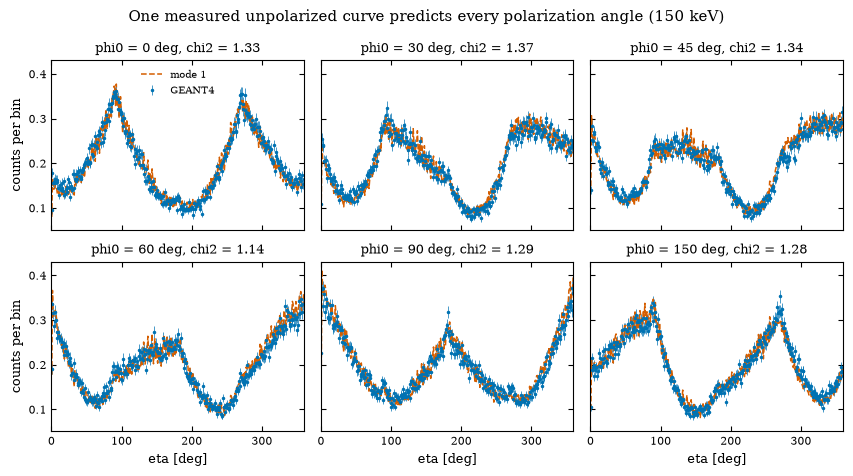

In [ ]:
angles = (0.0, 30.0, 45.0, 60.0, 90.0, 150.0)
fig, axes = plt.subplots(2, 3, figsize=(8.6, 4.8), sharex=True, sharey=True)
for ax, phi0 in zip(axes.ravel(), angles):
    sim = polar.load_polarized(ENERGY, phi0)
    p, perr = build_single(m_unp, edges, ENERGY, DELTA, LAMBDA, phi0, GATE,
                           errors=m_unp_err)
    chi2, chi2_err, _ = calculate_reduced_chi_squared(sim.counts, sim.errors, p, perr, norm=NORM_FACTOR)
    ax.errorbar(eta, sim.counts, yerr=sim.errors, fmt=palette.mk("reference"), ms=1.5,
                lw=0.5, color=palette.c("reference"), label="GEANT4")
    ax.plot(eta, p, lw=1.1, color=palette.c("mode1"), ls=palette.ls("mode1"), label="mode 1")
    ax.set_title(f"phi0 = {phi0:.0f} deg, chi2 = {chi2:.2f}")
    ax.set_xlim(0, 360)
axes[0, 0].legend(frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("eta [deg]")
for ax in axes[:, 0]:
    ax.set_ylabel("counts per bin")
fig.suptitle("One measured unpolarized curve predicts every polarization angle (150 keV)")
fig.tight_layout()
plt.show()
# Caption: points are the independent GEANT4 simulations at six
# polarization angles; the dashed lines are the mode 1 predictions from
# the single unpolarized input. All panels share the energy, geometry and
# gate of the worked example.


## Where to go next

The next notebook (`02_sample_data_and_first_run.ipynb`) runs the same prediction on the sample data the package ships, which need no external file, and then on a POLAR file with a few lines. The third notebook (`03_full_demo_170114A.ipynb`) scales this up to the full energy grid and both response modes of the package.